# Retail Sales Analysis 2025

**What drives revenue and profit in a small retail shop, and what should it do next?**

This report analyses one year of orders (914 orders, three sales channels, four product categories) with Python, pandas and matplotlib. It answers six business questions and ends with recommendations.

> Portfolio project. **The dataset is synthetic**: it was generated for demonstration and describes no real business. The findings are true for this dataset, and the methods carry over to real data.

**Contents**
1. Data check
2. Headline numbers
3. Seasonality: when does the shop earn?
4. Categories: what earns the profit?
5. Channels: how do in-store, online and phone differ?
6. Customers: new vs returning
7. Weekdays and order size
8. Recommendations

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter

pd.set_option("display.float_format", "{:,.2f}".format)

NAVY, TEAL, SAND, CORAL, GREY = "#1f3a5f", "#2a9d8f", "#e9c46a", "#e76f51", "#9aa5b1"
CHANNEL_COLORS = {"In-store": NAVY, "Online": TEAL, "Phone": SAND}
plt.rcParams.update({
    "figure.figsize": (10, 4.2), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": "#e9edf2",
    "axes.axisbelow": True, "font.size": 10,
})
usd = FuncFormatter(lambda v, _: f"${v:,.0f}")

def save(fig, name):
    fig.savefig(f"figures/{name}.png", bbox_inches="tight", dpi=150)

def table(df, money=(), money2=(), pct=(), signed=(), ints=()):
    """Show a table with $, % and thousands separators."""
    fmt = {**{c: "${:,.0f}" for c in money}, **{c: "${:,.2f}" for c in money2},
           **{c: "{:.1%}" for c in pct}, **{c: "{:+.0%}" for c in signed}, **{c: "{:,.0f}" for c in ints}}
    return df.style.format(fmt, na_rep="–")

## 1. Data check

Load the orders and the cost-of-goods (COGS) assumptions, then check for gaps, duplicates and the date range before analysing anything.

In [2]:
orders = pd.read_csv("data/Orders.csv", parse_dates=["Date"])
cogs = pd.read_csv("data/Categories.csv").set_index("Category")["COGS_Pct"]

checks = pd.Series({
    "Rows": len(orders),
    "Missing values": int(orders.isna().sum().sum()),
    "Duplicate order IDs": int(orders["OrderID"].duplicated().sum()),
    "First date": orders["Date"].min().date(),
    "Last date": orders["Date"].max().date(),
    "Non-positive units or prices": int(((orders["Units"] <= 0) | (orders["UnitPrice"] <= 0)).sum()),
    "Categories without COGS %": int((~orders["Category"].isin(cogs.index)).sum()),
})
checks.to_frame("Value")

,Value
Rows,914
Missing values,0
Duplicate order IDs,0
First date,2025-01-01
Last date,2025-12-31
Non-positive units or prices,0
Categories without COGS %,0


In [3]:
orders["Revenue"] = orders["Units"] * orders["UnitPrice"]
orders["COGS"] = orders["Revenue"] * orders["Category"].map(cogs)
orders["GrossProfit"] = orders["Revenue"] - orders["COGS"]
orders["Month"] = orders["Date"].dt.month
orders["MonthName"] = orders["Date"].dt.strftime("%b")
orders["Weekday"] = orders["Date"].dt.day_name().str[:3]
orders.head()

,OrderID,Date,Channel,Category,Customer,Units,UnitPrice,Revenue,COGS,GrossProfit,Month,MonthName,Weekday
0,ORD-0001,2025-01-01,Online,Events & weddings,Returning,1,466.26,466.26,186.50,279.76,1,Jan,Wed
1,ORD-0002,2025-01-01,Phone,Bouquets,New,1,74.28,74.28,33.43,40.85,1,Jan,Wed
2,ORD-0003,2025-01-01,Online,Gifts & add-ons,Returning,1,28.13,28.13,15.47,12.66,1,Jan,Wed
3,ORD-0004,2025-01-01,In-store,Gifts & add-ons,New,2,22.87,45.74,25.16,20.58,1,Jan,Wed
4,ORD-0005,2025-01-02,In-store,Bouquets,New,1,62.05,62.05,27.92,34.13,1,Jan,Thu


The data is clean: one row per order, no gaps or duplicates, every date inside 2025, every category has a cost-of-goods %. Revenue = units × unit price; gross profit = revenue − COGS.

## 2. Headline numbers

In [4]:
def kpis(df):
    rev, gp, n = df["Revenue"].sum(), df["GrossProfit"].sum(), len(df)
    return pd.Series({"Revenue": rev, "Gross profit": gp, "Gross margin": gp / rev, "Orders": n,
                      "Avg order value": rev / n, "Median order value": df["Revenue"].median(),
                      "Returning customers": (df["Customer"] == "Returning").mean()})

headline = kpis(orders)
pd.DataFrame({"Value": [f"${headline['Revenue']:,.2f}", f"${headline['Gross profit']:,.2f}",
                        f"{headline['Gross margin']:.1%}", f"{headline['Orders']:,.0f}",
                        f"${headline['Avg order value']:,.2f}", f"${headline['Median order value']:,.2f}",
                        f"{headline['Returning customers']:.1%}"]}, index=headline.index)

,Value
Revenue,"$58,482.14"
Gross profit,"$31,712.54"
Gross margin,54.2%
Orders,914
Avg order value,$63.98
Median order value,$48.37
Returning customers,45.6%


The **average** order is \$63.98 but the **median** is only \$48.37: a small number of large orders pulls the average up. Section 4 shows where they come from.

## 3. Seasonality: when does the shop earn?

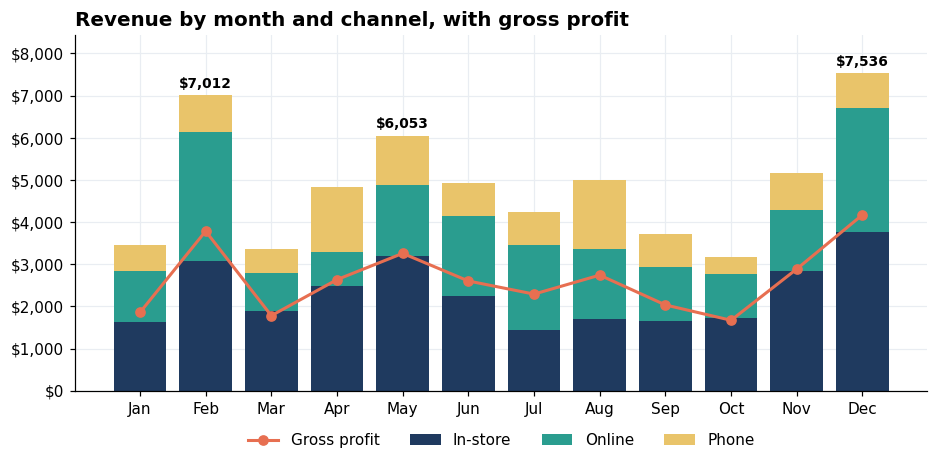

,Revenue,GrossProfit,Orders,Avg order,vs previous month
Month,,,,,
Jan,"$3,452","$1,856",63,$54.79,–
Feb,"$7,012","$3,785",110,$63.74,+103%
Mar,"$3,354","$1,780",59,$56.85,-52%
Apr,"$4,824","$2,635",73,$66.08,+44%
May,"$6,053","$3,258",108,$56.05,+25%
Jun,"$4,931","$2,603",86,$57.34,-19%
Jul,"$4,240","$2,291",56,$75.71,-14%
Aug,"$5,008","$2,742",80,$62.60,+18%
Sep,"$3,723","$2,034",56,$66.47,-26%


In [5]:
monthly = orders.groupby("Month").agg(Revenue=("Revenue", "sum"), GrossProfit=("GrossProfit", "sum"),
                                      Orders=("OrderID", "count"))
monthly["Avg order"] = monthly["Revenue"] / monthly["Orders"]
monthly["vs previous month"] = monthly["Revenue"].pct_change()
monthly.index = pd.to_datetime(monthly.index, format="%m").strftime("%b")

by_channel = orders.pivot_table(index="Month", columns="Channel", values="Revenue", aggfunc="sum")
fig, ax = plt.subplots()
bottom = 0
for ch in ["In-store", "Online", "Phone"]:
    ax.bar(monthly.index, by_channel[ch], bottom=bottom, color=CHANNEL_COLORS[ch], label=ch)
    bottom = bottom + by_channel[ch].values
ax.plot(monthly.index, monthly["GrossProfit"], color=CORAL, marker="o", lw=2, label="Gross profit")
for m in ["Feb", "May", "Dec"]:
    ax.annotate(f"${monthly.loc[m, 'Revenue']:,.0f}", (m, monthly.loc[m, 'Revenue']),
                ha="center", va="bottom", fontsize=9, fontweight="bold", xytext=(0, 3), textcoords="offset points")
ax.yaxis.set_major_formatter(usd)
ax.set_title("Revenue by month and channel, with gross profit")
ax.set_ylim(top=monthly["Revenue"].max() * 1.12)
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.08))
save(fig, "1_monthly_revenue")
plt.show()
table(monthly, money=["Revenue", "GrossProfit"], money2=["Avg order"], ints=["Orders"], signed=["vs previous month"])

In [6]:
peak = monthly.loc[["Feb", "May", "Dec"], "Revenue"].sum() / monthly["Revenue"].sum()
week_share = {
    "Valentine's week (Feb 7–14) in February": ("2025-02-07", "2025-02-14", 2),
    "Mother's Day week (May 5–11) in May": ("2025-05-05", "2025-05-11", 5),
    "Pre-Christmas (Dec 15–24) in December": ("2025-12-15", "2025-12-24", 12),
}
rows = {}
for label, (start, end, month) in week_share.items():
    in_week = orders[orders["Date"].between(start, end)]["Revenue"].sum()
    rows[label] = in_week / orders.loc[orders["Month"] == month, "Revenue"].sum()
print(f"Feb + May + Dec = {peak:.1%} of annual revenue")
pd.Series(rows, name="Share of the month's revenue").map("{:.0%}".format).to_frame()

Feb + May + Dec = 35.2% of annual revenue


,Share of the month's revenue
Valentine's week (Feb 7–14) in February,47%
Mother's Day week (May 5–11) in May,43%
Pre-Christmas (Dec 15–24) in December,49%


**Findings**
- Three months, **February, May and December, bring 35% of the year's revenue.** They line up with Valentine's Day, Mother's Day and the holidays.
- The peaks are short: **Valentine's week alone is 47% of February**, Mother's Day week is 43% of May, and the ten days before Christmas are 49% of December.
- February revenue doubles January (+103%) and then halves in March (−52%). October is the weakest month (\$3,182).
- Gross profit follows revenue closely: the margin stays in a narrow band all year.

## 4. Categories: what earns the profit?

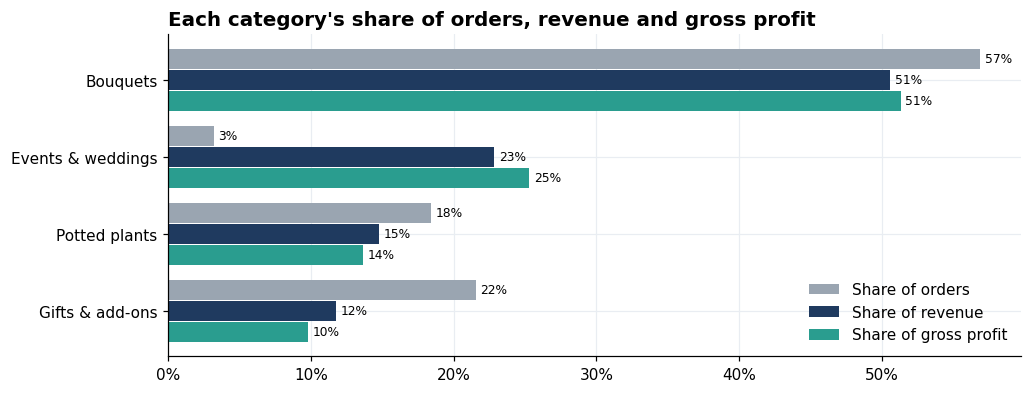

,Revenue,GrossProfit,Orders,Avg units,Margin,Avg order
Category,,,,,,
Bouquets,29592.290000,16275.759500,520,1.00,0.550000,56.908250
Events & weddings,13363.610000,8018.166000,29,1.00,0.600000,460.814138
Potted plants,8636.110000,4318.055000,168,1.40,0.500000,51.405417
Gifts & add-ons,6890.130000,3100.558500,197,1.42,0.450000,34.975279


In [7]:
cat = orders.groupby("Category").agg(Revenue=("Revenue", "sum"), GrossProfit=("GrossProfit", "sum"),
                                     Orders=("OrderID", "count"), AvgUnits=("Units", "mean"))
cat["Margin"] = cat["GrossProfit"] / cat["Revenue"]
cat["Avg order"] = cat["Revenue"] / cat["Orders"]
share = pd.DataFrame({"Orders": cat["Orders"] / cat["Orders"].sum(),
                      "Revenue": cat["Revenue"] / cat["Revenue"].sum(),
                      "Gross profit": cat["GrossProfit"] / cat["GrossProfit"].sum()})
cat = cat.sort_values("Revenue", ascending=False)
share = share.loc[cat.index]

fig, ax = plt.subplots(figsize=(10, 3.8))
y = range(len(share))
for k, (col, color) in enumerate([("Orders", GREY), ("Revenue", NAVY), ("Gross profit", TEAL)]):
    bars = ax.barh([i + (k - 1) * 0.27 for i in y], share[col], height=0.26, color=color, label=f"Share of {col.lower()}")
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in share[col]], padding=3, fontsize=8)
ax.set_yticks(list(y), share.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title("Each category's share of orders, revenue and gross profit")
ax.legend(frameon=False, loc="lower right")
save(fig, "2_category_shares")
plt.show()
table(cat.rename(columns={"AvgUnits": "Avg units"}), money=["Revenue", "GrossProfit"], money2=["Avg order"],
      pct=["Margin"], ints=["Orders"]).format({"Avg units": "{:.2f}"})

In [8]:
big = orders[orders["Revenue"] >= 300]
events_by_month = orders[orders["Category"] == "Events & weddings"].groupby("MonthName")["OrderID"].count()
print(f"Orders of $300+: {len(big)} ({len(big) / len(orders):.1%} of orders), "
      f"{big['Revenue'].sum() / orders['Revenue'].sum():.1%} of revenue; categories: {big['Category'].unique().tolist()}")
events_by_month.reindex(monthly.index, fill_value=0).to_frame("Event orders").T

Orders of $300+: 27 (3.0% of orders), 21.9% of revenue; categories: ['Events & weddings']


Month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Event orders,1,3,1,3,2,1,2,3,3,0,4,6


**Findings**
- **Events & weddings** are only **3% of orders but 23% of revenue and 25% of gross profit**, with the best margin (60%) and an average order of \$461. All 27 orders above \$300 are events, and they alone bring 22% of revenue.
- That income is lumpy: there were **no event orders at all in October**, which is the main reason it is the weakest month.
- **Bouquets** are the core business: 57% of orders and about half of revenue and profit.
- **Gifts & add-ons** are 22% of orders but only 12% of revenue and 10% of profit, with the lowest margin (45%) and a \$35 average order. They work as small add-ons, not as a product line of their own.

## 5. Channels: how do in-store, online and phone differ?

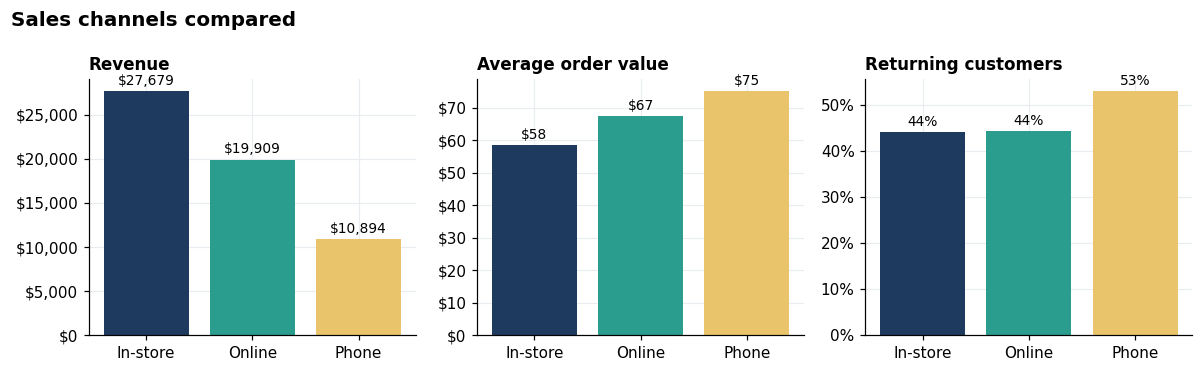

,Revenue,GrossProfit,Orders,Margin,Avg order,Returning share,Events share of revenue
Channel,,,,,,,
In-store,"$27,679","$14,890",474,53.8%,$58.39,44.1%,14.8%
Online,"$19,909","$10,851",295,54.5%,$67.49,44.4%,26.2%
Phone,"$10,894","$5,971",145,54.8%,$75.13,53.1%,37.1%


In [9]:
ch = orders.groupby("Channel").agg(Revenue=("Revenue", "sum"), GrossProfit=("GrossProfit", "sum"),
                                   Orders=("OrderID", "count"))
ch["Margin"] = ch["GrossProfit"] / ch["Revenue"]
ch["Avg order"] = ch["Revenue"] / ch["Orders"]
ch["Returning share"] = orders.groupby("Channel")["Customer"].apply(lambda s: (s == "Returning").mean())
ch["Events share of revenue"] = (orders[orders["Category"] == "Events & weddings"].groupby("Channel")["Revenue"].sum()
                                 / ch["Revenue"])
ch = ch.sort_values("Revenue", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, col, fmt, title in [(axes[0], "Revenue", usd, "Revenue"),
                            (axes[1], "Avg order", usd, "Average order value"),
                            (axes[2], "Returning share", PercentFormatter(1), "Returning customers")]:
    bars = ax.bar(ch.index, ch[col], color=[CHANNEL_COLORS[c] for c in ch.index])
    ax.yaxis.set_major_formatter(fmt)
    ax.bar_label(bars, labels=[f"{v:.0%}" if col == "Returning share" else f"${v:,.0f}" for v in ch[col]],
                 padding=2, fontsize=9)
    ax.set_title(title, fontsize=11)
fig.suptitle("Sales channels compared", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "3_channels")
plt.show()
table(ch, money=["Revenue", "GrossProfit"], money2=["Avg order"], ints=["Orders"],
      pct=["Margin", "Returning share", "Events share of revenue"])

**Findings**
- **In-store** brings the most revenue (47%) with the smallest orders (\$58 on average): mostly everyday bouquets.
- **Phone** is the smallest channel (19% of revenue) but has the **highest average order (\$75)** and the **most returning customers (53%)**. 37% of its revenue is events: people call to order big arrangements.
- **Online** sits in between, with an average order of \$67 and a quarter of its revenue from events.
- Margins are almost the same in every channel (54–55%), so the channels differ in *what* people buy, not in pricing.

## 6. Customers: new vs returning

In [10]:
cust = orders.groupby("Customer").agg(Revenue=("Revenue", "sum"), Orders=("OrderID", "count"),
                                      AvgOrder=("Revenue", "mean"), AvgUnits=("Units", "mean"))
cust["Share of orders"] = cust["Orders"] / cust["Orders"].sum()
cust["Share of revenue"] = cust["Revenue"] / cust["Revenue"].sum()
table(cust.rename(columns={"AvgOrder": "Avg order", "AvgUnits": "Avg units"}), money=["Revenue"],
      money2=["Avg order"], ints=["Orders"], pct=["Share of orders", "Share of revenue"]).format({"Avg units": "{:.2f}"})

,Revenue,Orders,Avg order,Avg units,Share of orders,Share of revenue
Customer,,,,,,
New,33052.580000,497,66.504185,1.21,0.543764,0.565174
Returning,25429.560000,417,60.982158,1.11,0.456236,0.434826


**Findings**
- **Returning customers place 46% of orders and bring 43% of revenue.** Their average order (\$61) is a little below new customers' (\$67).
- So loyalty is already strong: almost every second order is a repeat. The opportunity is to make repeat orders bigger, for example with an add-on offer.

## 7. Weekdays and order size

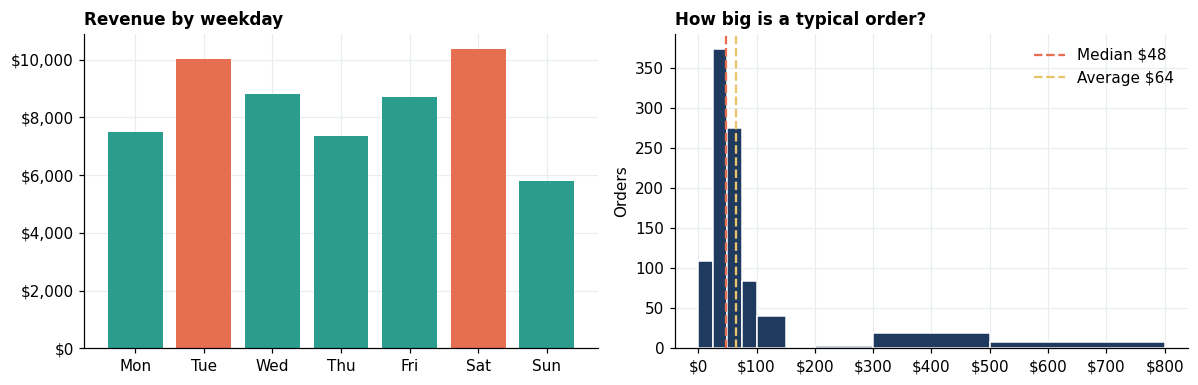

,Revenue,Orders,Avg order
Weekday,,,
Mon,"$7,493",135,$55.50
Tue,"$10,026",145,$69.14
Wed,"$8,798",146,$60.26
Thu,"$7,334",111,$66.08
Fri,"$8,693",144,$60.37
Sat,"$10,360",155,$66.84
Sun,"$5,779",78,$74.09


In [11]:
order_wd = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
wd = orders.groupby("Weekday").agg(Revenue=("Revenue", "sum"), Orders=("OrderID", "count")).reindex(order_wd)
wd["Avg order"] = wd["Revenue"] / wd["Orders"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
bars = ax1.bar(wd.index, wd["Revenue"], color=[CORAL if d in ("Tue", "Sat") else TEAL for d in wd.index])
ax1.yaxis.set_major_formatter(usd)
ax1.set_title("Revenue by weekday", fontsize=11)
ax2.hist(orders["Revenue"], bins=[0, 25, 50, 75, 100, 150, 200, 300, 500, 800], color=NAVY, edgecolor="white")
ax2.axvline(orders["Revenue"].median(), color=CORAL, ls="--", lw=1.5, label=f"Median ${orders['Revenue'].median():,.0f}")
ax2.axvline(orders["Revenue"].mean(), color=SAND, ls="--", lw=1.5, label=f"Average ${orders['Revenue'].mean():,.0f}")
ax2.xaxis.set_major_formatter(usd)
ax2.set_title("How big is a typical order?", fontsize=11)
ax2.set_ylabel("Orders")
ax2.legend(frameon=False)
fig.tight_layout()
save(fig, "4_weekdays_order_size")
plt.show()
table(wd, money=["Revenue"], money2=["Avg order"], ints=["Orders"])

**Findings**
- **Saturday and Tuesday are the strongest days** (about \$10,000 each over the year). **Sunday is the quietest** (78 orders, half of Saturday) but has the **largest average order (\$74)**.
- Most orders are small: three quarters are under \$66. The long tail on the right is the event orders from section 4.

## 8. Recommendations

Based on this dataset:

1. **Plan for three short peaks.** Valentine's week, Mother's Day week and the ten days before Christmas bring a large part of the year's revenue. Stock, staff and marketing should be booked for those weeks, with pre-orders opened two to three weeks before.
2. **Grow the events business on purpose.** Events are 3% of orders and a quarter of gross profit, and they fill the quiet months. A clear event package page, a quote form and follow-ups for weddings in the autumn could reduce gaps like October's.
3. **Sell gifts as add-ons to bouquets.** On their own they are small and low-margin. Offered at checkout (card + chocolates, vase), they raise the average bouquet order.
4. **Look after phone customers.** They spend the most per order and come back most often. A callback list and early access to holiday pre-orders suit this group.
5. **Make repeat orders bigger.** Returning customers already make 46% of orders. A small loyalty perk tied to a minimum order value targets their slightly smaller basket.
6. **Check Sunday opening hours.** Sunday has the fewest orders but the largest baskets. Comparing staffing cost with Sunday gross profit would show whether shorter hours or a Sunday-only offer pays off.

*Method note: gross profit uses a fixed cost-of-goods % per category. With real data, the next steps would be comparing with the previous year, checking stock-outs and testing the add-on offer before rolling it out.*